# Stage 4 v2 ? Intrinsic Karst Vulnerability (Mole Creek prototype)

Combines Stage 2 karst intensity and exposure with Stage 7.1 log-scale D8 hydrological connectivity into **intrinsic karst vulnerability**. This answers: *if something happens on the surface, where is the underlying karst system relatively more vulnerable?*

**Combination method:** multiply the three normalized inputs: `intensity_norm * exposure_norm * connectivity_D8_norm`. The Stage 2 scales are normalized by their maxima (intensity 0?4, exposure 0?3); the Stage 7.1 log-scale D8 connectivity classes (1?4) are normalized by 4. The DEM valid-data mask determines which cells are included.


In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from rasterio.warp import reproject, Resampling

sys.path.insert(0, str(Path("..") / "src"))
from karst import classify_scores
from mapping import add_attribution, add_basemap, data_bounds, finish_map, plot_scores, scores_legend

data = Path(os.environ.get("AT3_DATA_DIR", "data"))
outpath = data / "Output_data"

# Use the core DEM as the target grid and analysis mask.
with rasterio.open(outpath / "dem_mc_core_EPSG7855.tif") as core_src:
    core_crs = core_src.crs
    if core_crs is None:
        raise ValueError("The Mole Creek core DEM has no CRS")
    if core_crs.to_epsg() != 7855:
        raise ValueError(f"Expected core DEM in EPSG:7855; found {core_crs}")
    core_shape = core_src.shape
    core_transform = core_src.transform
    profile = core_src.profile.copy()
    core_dem_masked = core_src.read(1, masked=True)
    dem_mask = (core_src.dataset_mask() > 0) & ~np.ma.getmaskarray(core_dem_masked)
    dem = np.asarray(core_dem_masked.astype("float32").filled(-9999), dtype="float32")
    dem_nodata = core_src.nodata

GRID_NODATA = -9999.0
def read_on_core_grid(filename, layer_name):
    """Read a categorical score raster, warping it to the core DEM grid if needed."""
    source_path = outpath / filename
    with rasterio.open(source_path) as src:
        if src.crs is None:
            raise ValueError(f"{layer_name} raster has no CRS: {source_path}")
        source_masked = src.read(1, masked=True)
        source_data = np.asarray(source_masked.astype("float32").filled(GRID_NODATA), dtype="float32")
        source_data[~np.isfinite(source_data)] = GRID_NODATA
        aligned = (
            src.shape == core_shape
            and src.transform == core_transform
            and src.crs == core_crs
        )
        if aligned:
            result = source_data
            print(f"{layer_name}: already matches the core DEM grid ({src.crs}, {src.res})")
        else:
            result = np.full(core_shape, GRID_NODATA, dtype="float32")
            reproject(
                source=source_data,
                destination=result,
                src_transform=src.transform,
                src_crs=src.crs,
                src_nodata=GRID_NODATA,
                dst_transform=core_transform,
                dst_crs=core_crs,
                dst_nodata=GRID_NODATA,
                resampling=Resampling.nearest,
                init_dest_nodata=True,
            )
            print(
                f"{layer_name}: aligned to core DEM grid using nearest neighbour "
                f"(source {src.crs}, {src.res}, {src.shape}; target {core_crs}, "
                f"{profile['transform'].a, -profile['transform'].e}, {core_shape})"
            )
    return result

intensity = read_on_core_grid("karst_intensity_mc_EPSG7855.tif", "Intensity")
exposure = read_on_core_grid("karst_exposure_mc_EPSG7855.tif", "Exposure")
connectivity_d8 = read_on_core_grid(
    "connectivity_logscale4_mc_25m_EPSG7855_alt3.tif", "Log-scale D8 connectivity"
)

# Require valid core DEM cells and valid coverage from all three inputs.
valid = (
    dem_mask
    & (intensity != GRID_NODATA)
    & (exposure != GRID_NODATA)
    & (connectivity_d8 != GRID_NODATA)
)
print(f"Core DEM grid: {core_shape}, {core_crs}, resolution {profile['transform'].a, -profile['transform'].e}")
print(f"Valid cells inside core with all three inputs: {int(valid.sum()):,}")


## 4.1 Normalise and combine

Normalize the Stage 2 intensity (0?4), Stage 2 exposure (0?3), and Stage 7.1 log-scale D8 connectivity (1?4) to 0?1, then multiply them cell by cell.


In [15]:
intensity_norm = intensity / 4.0          # max KCATEGORY score from Stage 2
exposure_norm = exposure / 3.0            # max exposure score from Stage 2
connectivity_D8_norm = connectivity_d8 / 4.0  # max log-scale D8 class from Stage 7.1

intrinsic = intensity_norm * exposure_norm * connectivity_D8_norm
intrinsic[~valid] = np.nan

print("Distinct combined score values present:", np.unique(intrinsic[valid]))


Distinct combined score values present: [0.         0.0625     0.08333333 0.125      0.16666667 0.1875
 0.25       0.33333333 0.375      0.5        0.66666667 0.75      ]


## 4.2 Classify

Classified directly on whatever distinct combined values occur (via `classify_scores()` in `src/karst.py`). A handful of discrete ordinal inputs produces only a few real combinations, so exact-value classes are more meaningful than quantile breaks. Labels are generated from the values present, so a change to the upstream scoring flows through without edits here.

Class distribution (valid cells):
  Class 0 (0.000) (score=0.0000): 1435887 cells (77.7%)
  Class 1 (0.062) (score=0.0625): 28511 cells (1.5%)
  Class 2 (0.083) (score=0.0833): 6270 cells (0.3%)
  Class 3 (0.125) (score=0.1250): 24111 cells (1.3%)
  Class 4 (0.167) (score=0.1667): 132825 cells (7.2%)
  Class 5 (0.188) (score=0.1875): 2554 cells (0.1%)
  Class 6 (0.250) (score=0.2500): 172332 cells (9.3%)
  Class 7 (0.333) (score=0.3333): 17729 cells (1.0%)
  Class 8 (0.375) (score=0.3750): 438 cells (0.0%)
  Class 9 (0.500) (score=0.5000): 27379 cells (1.5%)
  Class 10 (0.667) (score=0.6667): 51 cells (0.0%)
  Class 11 (0.750) (score=0.7500): 323 cells (0.0%)


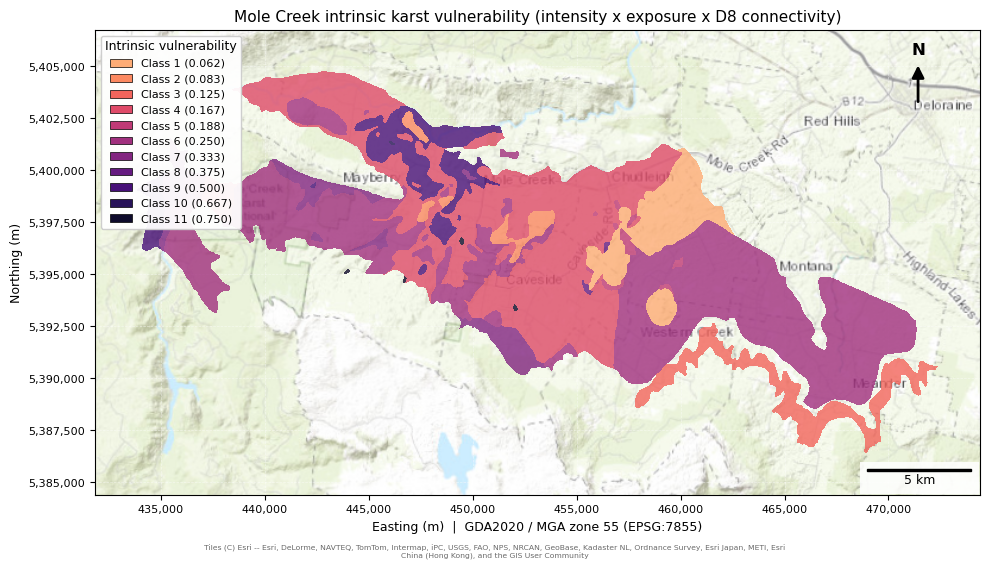

In [16]:
intrinsic_class, present, LABELS = classify_scores(intrinsic, valid)

print("Class distribution (valid cells):")
for i, (val, label) in enumerate(zip(present, LABELS)):
    n = (intrinsic_class == i).sum()
    print(f"  {label} (score={val:.4f}): {n} cells ({n/valid.sum()*100:.1f}%)")

out_profile = profile.copy()
out_profile.update(dtype="uint8", nodata=255)
with rasterio.open(outpath / "intrinsic_vulnerability_v2_mc_EPSG7855.tif", "w", **out_profile) as dst:
    dst.write(intrinsic_class, 1)

# Also save the continuous (unclassified) score -- Stage 6 needs the real
# relative spacing, not the class index, which would distort it
intrinsic_raw = np.where(valid, intrinsic, -9999).astype("float32")
raw_profile = profile.copy()
raw_profile.update(dtype="float32", nodata=-9999)
with rasterio.open(outpath / "intrinsic_vulnerability_v2_raw_mc_EPSG7855.tif", "w", **raw_profile) as dst:
    dst.write(intrinsic_raw, 1)

bounds = data_bounds(valid & (intrinsic > 0), profile["transform"])
fig, ax = plt.subplots(figsize=(10, 5.6))
add_basemap(ax, bounds, zoom=11)
plot_scores(ax, intrinsic_class, profile["transform"], len(present))
scores_legend(ax, LABELS, title="Intrinsic vulnerability")
ax.set_title("Mole Creek intrinsic karst vulnerability (intensity x exposure x D8 connectivity)", fontsize=11)
finish_map(ax)
add_attribution(ax)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()


## Three-factor intrinsic vulnerability

This version combines intensity, exposure, and log-scale D8 connectivity. Exposure and connectivity both affect the result, so a high intensity score alone does not produce a high intrinsic vulnerability score where either exposure or connectivity is low. Connectivity is scored from the Stage 7.1 four-class log-scale classification in `03alt3_hydrological_connectivity`.


## Stage 4 v2 outputs

- `intrinsic_vulnerability_v2_mc_EPSG7855.tif` ? classified three-factor intrinsic vulnerability (class labels are generated from values present)
- `intrinsic_vulnerability_v2_raw_mc_EPSG7855.tif` ? continuous, unclassified three-factor score for downstream use

**Next (Stage 5):** land-use pressure from DEA Level-3 land cover, the first layer that should vary outside the karst polygons themselves, now that the Mole Creek boundary includes surrounding land (see the buffer in Stage 0).


## Five-class map of the final intrinsic vulnerability index

This separate map classifies the saved continuous intrinsic vulnerability raster using its original, unrounded positive values; it does not recalculate the index or alter the Stage 4.2 map. Zero-score and existing NoData cells are excluded from classification and shown transparently. The figure reuses the Stage 4.2 positive-score bounds, 10 ? 5.6 inch dimensions, basemap placement, score plotting and legend helpers, map frame, and attribution.

| Class | Label | Score range |
| ---: | --- | --- |
| 1 | Very low | 0 < s ? 0.125 |
| 2 | Low | 0.125 < s ? 0.1875 |
| 3 | Moderate | 0.1875 < s ? 0.25 |
| 4 | High | 0.25 < s ? 0.5 |
| 5 | Very high | 0.5 < s ? 0.75 |

The following cell prints the class counts and percentages and saves this classified map as a separate figure.

Classified positive cells (zero and NoData excluded): 412,523


,Class,Label,Score range,Valid cells,Percent of classified cells
0,1,Very low,0 < s ? 0.125,58892,14.28
1,2,Low,0.125 < s ? 0.1875,135379,32.82
2,3,Moderate,0.1875 < s ? 0.25,172332,41.78
3,4,High,0.25 < s ? 0.5,45546,11.04
4,5,Very high,0.5 < s ? 0.75,374,0.09


Saved classified vulnerability map: c:\Users\innoc\Documents\Uni\KGG375\AT3\AT3_Group3_2026\outputs\hydrological_connectivity_maps_alt3_core_karst_outlines\intrinsic_vulnerability_v2_5class.png


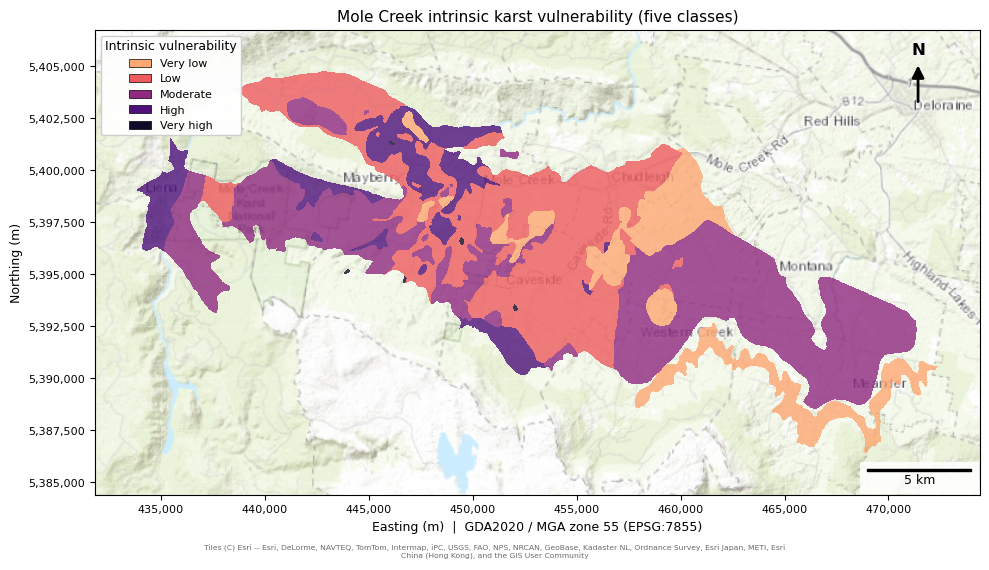

In [24]:
# Classify the saved continuous score at the exact breaks, then map it with the Stage 4.2 style.
import pandas as pd
from IPython.display import display
from mapping import score_colours

score_path = outpath / "intrinsic_vulnerability_v2_raw_mc_EPSG7855.tif"
with rasterio.open(score_path) as score_src:
    score_masked = score_src.read(1, masked=True)
    score_values = np.asarray(score_masked.data, dtype="float64")
    score_valid = (~np.ma.getmaskarray(score_masked)) & np.isfinite(score_values)
    score_transform = score_src.transform
    score_crs = score_src.crs
    score_shape = score_src.shape

if score_crs != profile["crs"] or score_transform != profile["transform"] or score_shape != (profile["height"], profile["width"]):
    raise ValueError("Saved intrinsic score raster does not match the Stage 4.2 core DEM grid")

# Apply the stated upper-inclusive ranges to original, unrounded raster values.
positive = score_valid & (score_values > 0)
class_conditions = [
    (score_values > 0) & (score_values <= 0.125),
    (score_values > 0.125) & (score_values <= 0.1875),
    (score_values > 0.1875) & (score_values <= 0.25),
    (score_values > 0.25) & (score_values <= 0.5),
    (score_values > 0.5) & (score_values <= 0.75),
]
class_labels = ["Very low", "Low", "Moderate", "High", "Very high"]
# Use Stage 4.2's magma_r palette, sampling its positive-score colours so class 1 stays opaque.
stage42_colours = score_colours(len(LABELS), zero_transparent=False)
colour_indices = np.rint(np.linspace(1, len(LABELS) - 1, len(class_labels))).astype(int)
class_colours = stage42_colours[colour_indices]
class_ranges = [
    "0 < s ? 0.125",
    "0.125 < s ? 0.1875",
    "0.1875 < s ? 0.25",
    "0.25 < s ? 0.5",
    "0.5 < s ? 0.75",
]
above_range = positive & (score_values > 0.75)
if above_range.any():
    raise ValueError(f"Positive scores exceed the specified class range; maximum is {score_values[above_range].max():.9g}")
class_raster = np.full(score_shape, 255, dtype="uint8")
class_counts = []
for class_index, condition in enumerate(class_conditions):
    selected = score_valid & condition
    class_raster[selected] = class_index
    class_counts.append(int(selected.sum()))
class_counts = np.asarray(class_counts, dtype="int64")
classified_count = int(class_counts.sum())
if classified_count == 0:
    raise ValueError("No positive, non-NoData intrinsic scores fall within the specified classes")

break_table = pd.DataFrame({
    "Class": range(1, 6),
    "Label": class_labels,
    "Score range": class_ranges,
    "Valid cells": class_counts,
    "Percent of classified cells": [round(count / classified_count * 100, 2) for count in class_counts],
})
print(f"Classified positive cells (zero and NoData excluded): {classified_count:,}")
display(break_table)

# Match the Stage 4.2 bounds, figure dimensions, map placement, and plotting helpers.
bounds = data_bounds(positive, profile["transform"])
fig, ax = plt.subplots(figsize=(10, 5.6))
add_basemap(ax, bounds, zoom=11)
plot_scores(ax, class_raster, profile["transform"], len(class_labels), colours=class_colours)
scores_legend(ax, class_labels, title="Intrinsic vulnerability", skip=(), colours=class_colours)
ax.set_title("Mole Creek intrinsic karst vulnerability (five classes)", fontsize=11)
finish_map(ax)
add_attribution(ax)
plt.tight_layout(rect=(0, 0.04, 1, 1))

project_root = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
map_output_dir = project_root / "outputs" / "hydrological_connectivity_maps_alt3_core_karst_outlines"
map_output_dir.mkdir(parents=True, exist_ok=True)
map_path = map_output_dir / "intrinsic_vulnerability_v2_5class.png"
fig.savefig(map_path, dpi=180, facecolor="white")
print(f"Saved classified vulnerability map: {map_path}")
plt.show()
